In [142]:
import pandas as pd

In [288]:
#df = pd.read_csv("all_data_no_reflection.csv")
df = pd.read_csv("all_data_allmodels_vart2_4con.csv")
#df = pd.read_csv("all_data_s1.csv")

In [278]:
df_filtered = df[(df['type'] == 'S2') & (df['sub_type'] == 's2')]
#df_filtered = df[(df['t2']==1)]
df_filtered.groupby(['type','sub_type'])['length'].mean()
#df_filtered

type  sub_type
S2    s2          7.1086
Name: length, dtype: float64

In [244]:
df_filtered = df[(df['t2']== 1.5)]
df_filtered.groupby('type')['time'].mean()


type
S1 ra=0.0                   0.3384
S1 ra=0.25                  1.5816
S1 ra=0.5                   1.5854
S1 ra=0.75                  1.6364
S1 ra=1.0                   7.2208
SOFAI w/ S1 ra=0.0         59.5450
SOFAI w/ S1 ra=0.0 REF     64.3474
SOFAI w/ S1 ra=0.25        55.9236
SOFAI w/ S1 ra=0.25 REF    59.3970
SOFAI w/ S1 ra=0.5         43.0902
SOFAI w/ S1 ra=0.5 REF     52.4586
SOFAI w/ S1 ra=0.75        32.8312
SOFAI w/ S1 ra=0.75 REF    44.9518
SOFAI w/ S1 ra=1.0         18.2534
SOFAI w/ S1 ra=1.0 REF     28.0588
Name: time, dtype: float64

In [294]:
def getStats(tipo, label, dataframe):
	if label == 'avg_time':
		riga = '& Avg. Time (ms) & '
	elif label == 'time':
		riga = '& Avg. Time (ms) & '
	elif label == 'viol_constr':
		riga = '& Avg. Viol. Constr. & '
	else:	
		riga = '& Avg. '+label+' & '
	means= dataframe.groupby(tipo)[label].mean()
	stds= dataframe.groupby(tipo)[label].std()
	i=0
	#print(f"LEN: {len(means)}")
	for s in means:
		riga += str(round(s,2))+ " ("+ str(round(stds[i],2)) + ")"
		if i < 4:
			riga += " & "
		else:
			riga += " \\\\ \n"

		i += 1

	return riga

def getStatsNew(tipo, label, dataframe):
	list_labels_S2 = ['S2',]
	list_labels_S1 = ['S1 ra=0.0', 'S1 ra=0.25', 'S1 ra=0.5', 'S1 ra=0.75', 'S1 ra=1.0']
	list_label_SOFAI = ['SOFAI w/ S1 ra=0.0', 'SOFAI w/ S1 ra=0.25',
        'SOFAI w/ S1 ra=0.5',
        'SOFAI w/ S1 ra=0.75',
        'SOFAI w/ S1 ra=1.0']
	list_label_SOFAI_REF = ['SOFAI w/ S1 ra=0.0 REF', 
       'SOFAI w/ S1 ra=0.25 REF',
       'SOFAI w/ S1 ra=0.5 REF', 
       'SOFAI w/ S1 ra=0.75 REF',
       'SOFAI w/ S1 ra=1.0 REF']
	if label == 'avg_time':
		riga = '& Avg. Time (ms) & '
	elif label == 'time':
		riga = '& Avg. Time (ms) & '
	elif label == 'viol_constr':
		riga = '& Avg. Viol. Constr. & '
	else:	
		riga = '& Avg. '+label+' & '
	means= dataframe.groupby(tipo)[label].mean()
	stds= dataframe.groupby(tipo)[label].std()
	i=0
	#print(f"LEN: {len(means)}")
	for l in list_labels_SOFAI:
		riga += str(round(means[l],2))+ " ("+ str(round(stds[l],2)) + ")"
		if i < 4:
			riga += " & "
		else:
			riga += " \\\\ \n"

		i += 1

	return riga

In [ ]:
#list_threshold3 = [0, 0.25, 0.5, 0.75, 1]
list_threshold3 = [0, 0.5, 1]
list_threshold2 = [0.5, 0.95, 1, 1.5]
pRand = [0, 0.25, 0.5, 0.75, 1]

list_label = ['S1 ra=0.0', 'S1 ra=0.25', 'S1 ra=0.5', 'S1 ra=0.75', 'S1 ra=1.0',]
list_label = ['SOFAI w/ S1 ra=0.0', 'SOFAI w/ S1 ra=0.25', 'SOFAI w/ S1 ra=0.5', 'SOFAI w/ S1 ra=0.75', 'SOFAI w/ S1 ra=1.0',]

list_labels_S2 = ['S2',]
list_labels_S1 = ['S1 ra=0.0', 'S1 ra=0.25', 'S1 ra=0.5', 'S1 ra=0.75', 'S1 ra=1.0']
list_labels_SOFAI = ['SOFAI w/ S1 ra=0.0', 'SOFAI w/ S1 ra=0.25',
	'SOFAI w/ S1 ra=0.5',
	'SOFAI w/ S1 ra=0.75',
	'SOFAI w/ S1 ra=1.0']
list_labels_SOFAI_REF = ['SOFAI w/ S1 ra=0.0 REF', 
	'SOFAI w/ S1 ra=0.25 REF',
	'SOFAI w/ S1 ra=0.5 REF', 
	'SOFAI w/ S1 ra=0.75 REF',
	'SOFAI w/ S1 ra=1.0 REF']

print("\\begin{table*}[] \n \
\\begin{tabular}{llccccc} \n \
 &  & $pRand=1$ & $pRand=0.75$ & $pRand=0.5$ & $pRand=0.25$ & $pRand=0$ \\\\ \n \
")

'''for l in list_label:
	print("\\hline \n \\multirow{5}{*}{" + l + "} ", end=" ")
	df_filtered = df[(df['type'] == l )]

	print(getStats('type', 'time', df_filtered))
	print(getStats('type', 'reward', df_filtered))
	print(getStats('type', 'length', df_filtered))
	print(getStats('type', 'viol_constr', df_filtered))'''

for t2 in list_threshold2:
	print("\\hline \n \\multirow{5}{*}{SOFAI t2=" + str(round(t2,2)) + "} ", end=" ")
	#print("\\hline \n \\multirow{5}{*}{S1 solver } ", end=" ")
	#df_filtered = df[(df['type']=='S2') & (df['sub_type']=='s2')]
	df_filtered = df[(df['t2']==t2)]
	#df_filtered = df
	#if (t2==0):
	#	df_filtered = df[df['type']!= 'S2']
	'''means= df_filtered.groupby('type')['time'].mean()
	stds= df_filtered.groupby('type')['time'].std()
	i=0
	#print(f"LEN: {len(means)}")
	for s in means:
		print(str(round(s,2))+ " ("+ str(round(stds[i],2)) + ")", end=" ")
		if i < 4:
			print(" & ", end=" ")
		else:
			print(" \\\\ \n")

		i += 1'''
	print(getStatsNew('type', 'time', df_filtered))
	print(getStatsNew('type', 'reward', df_filtered))
	print(getStatsNew('type', 'length', df_filtered))
	print(getStatsNew('type', 'viol_constr', df_filtered))

	print('& Avg. Perc. Use S2 & ', end=" ")
	means= df_filtered.groupby(['type','sub_type'])['perc_usage'].mean()
	stds= df_filtered.groupby(['type','sub_type'])['perc_usage'].std()
	i=0
	#print(f"LEN: {len(means)}")
	riga = ""
	for l in list_labels_SOFAI:
		riga += str(round(means[l]['s2'],2))+ " ("+ str(round(stds[l]['s2'],2)) + ")"
		if i < 4:
			riga += " & "
		else:
			riga += " \\\\ \n"

		i += 1
	print(riga)
	

print(" \\hline \
\\end{tabular} \
    \\caption{} \
    \\label{tab:}\
\\end{table*}")

\begin{table*}[] 
 \begin{tabular}{llccccc} 
  &  & $pRand=1$ & $pRand=0.75$ & $pRand=0.5$ & $pRand=0.25$ & $pRand=0$ \\ 
 
\hline 
 \multirow{5}{*}{SOFAI t2=0.5}  & Avg. Time (ms) & 58.87 (100.79) & 48.22 (92.97) & 35.71 (82.3) & 26.92 (78.82) & 34.28 (88.4) \\ 

& Avg. reward & -1323.68 (1508.3) & -551.85 (538.44) & -310.75 (339.03) & -208.19 (312.43) & -206.64 (344.91) \\ 

& Avg. length & 40.43 (39.27) & 20.63 (18.15) & 14.59 (14.88) & 13.15 (16.76) & 44.12 (71.29) \\ 

& Avg. Viol. Constr. & 12.26 (23.31) & 5.01 (8.46) & 2.73 (4.94) & 1.7 (4.09) & 0.33 (1.5) \\ 

& Avg. Perc. Use S2 &  0.25 (0.24) & 0.25 (0.22) & 0.24 (0.22) & 0.2 (0.2) & 0.12 (0.18) \\ 

\hline 
 \multirow{5}{*}{SOFAI t2=0.95}  & Avg. Time (ms) & 58.87 (100.79) & 48.22 (92.97) & 35.71 (82.3) & 26.92 (78.82) & 34.28 (88.4) \\ 

& Avg. reward & -1323.68 (1508.3) & -551.85 (538.44) & -310.75 (339.03) & -208.19 (312.43) & -206.64 (344.91) \\ 

& Avg. length & 40.43 (39.27) & 20.63 (18.15) & 14.59 (14.88) & 13.15 (16.

/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_12660/4195353850.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp_df['sub_type'] = temp_df['sub_type'].map({'s1': 'S1', 's2': 'S2'})
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_12660/4195353850.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(x=x, y=y, data=temp_df, hue_order=['S1','S2'], ci=None, hue='sub_type', markers=True, dashes=False)


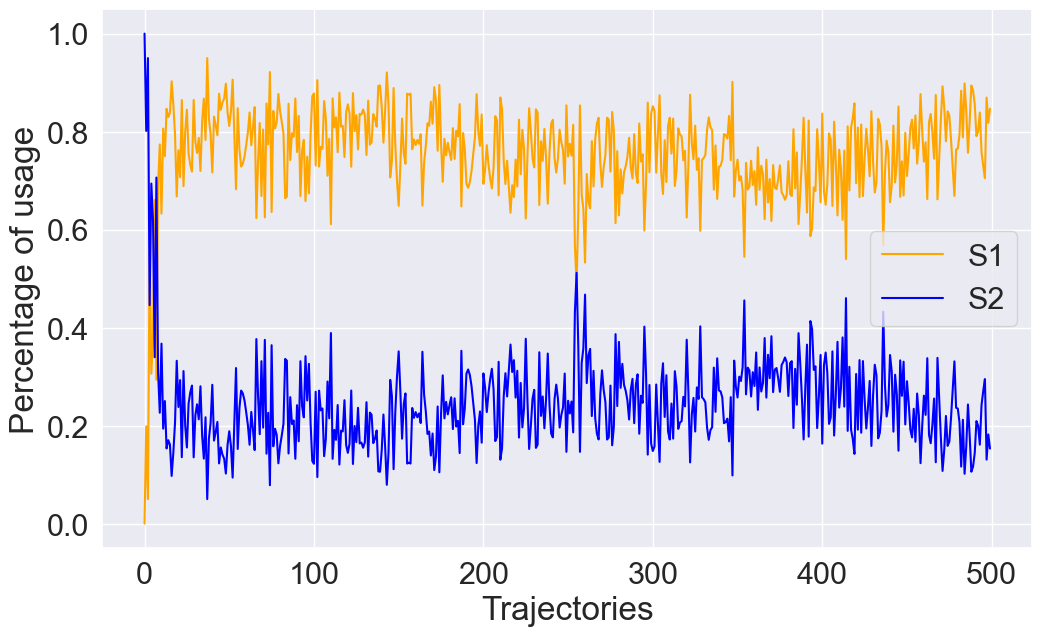

In [272]:
import matplotlib.pyplot as plt
import seaborn as sns

fig=plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")
sns.color_palette("viridis", as_cmap=True)
sns.set(font_scale=2)
x='traj_n'
y='perc_usage'
temp_df = df.loc[(df['type']=='SOFAI w/ S1 ra=1.0 REF') & (df['t2']== 1.0)]
temp_df['sub_type'] = temp_df['sub_type'].map({'s1': 'S1', 's2': 'S2'})


colors = ['orange', 'blue', '#E37346']
sns.set_palette(sns.color_palette(colors))

plt.legend(labels=['S1', 'S2'])
plt.xlabel("Trajectories")
plt.ylabel("Percentage of usage")

g=sns.lineplot(x=x, y=y, data=temp_df, hue_order=['S1','S2'], ci=None, hue='sub_type', markers=True, dashes=False)
g.legend_.set_title(None)
#plt.savefig(f'{y}.pdf', bbox_inches='tight')